In [1]:
import mlflow
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,root_mean_squared_error
from matplotlib import pyplot as plt

In [ ]:
mlflow.set_tracking_uri("sqlite:///D:\\repositories\\.mlflow\\mlflow.db")
mlflow.set_experiment(experiment_name="sales_predictor")
mlflow.autolog()

2026/07/30 18:32:48 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/07/30 18:32:48 INFO mlflow.store.db.utils: Updating database tables
2026/07/30 18:32:52 INFO mlflow.tracking.fluent: Experiment with name 'sales_predictor' does not exist. Creating a new experiment.
2026/07/30 18:33:01 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.


In [5]:
data = pd.read_csv('../../files/Advertising.csv')
data.head(5)

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


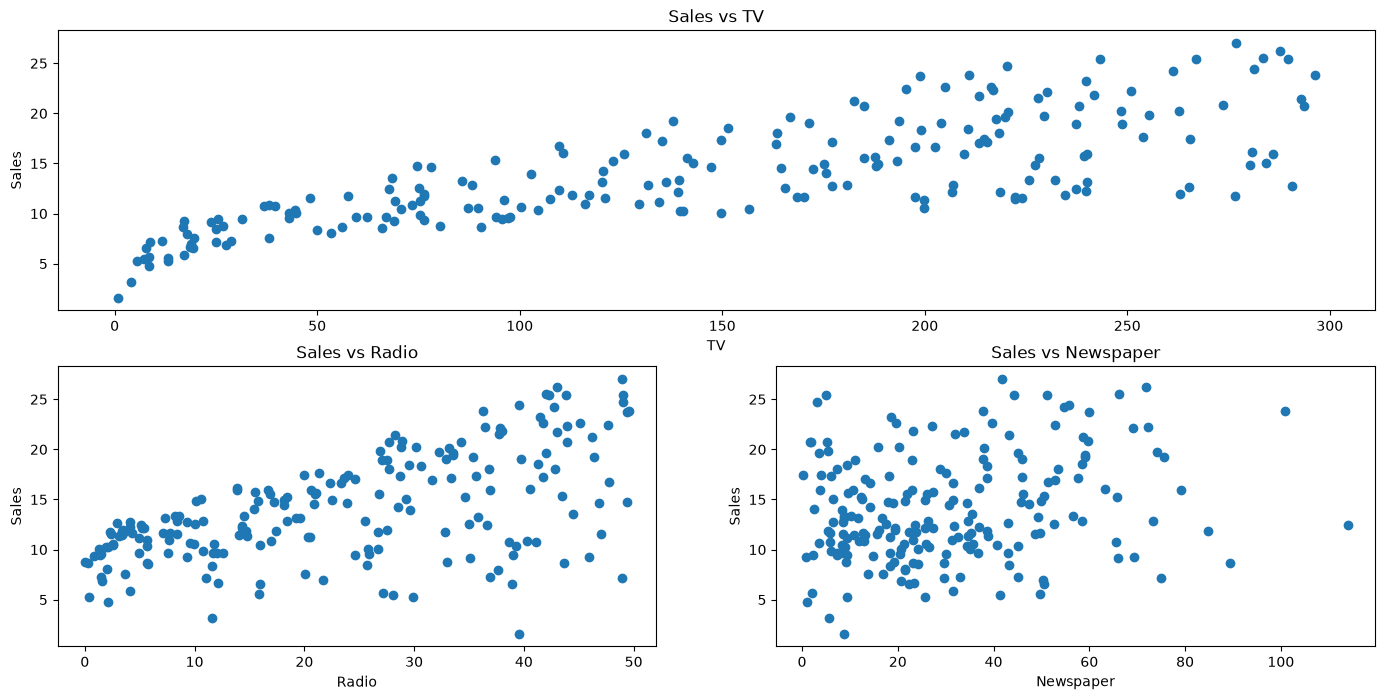

In [7]:
grid_shape = (2, 2)
plt.figure(figsize=(17, 8))

ax1 = plt.subplot2grid(shape=grid_shape, loc=(0, 0), colspan=2)
ax1.set_title("Sales vs TV")
ax1.scatter(data['TV'], data['Sales'])
ax1.set_xlabel("TV")
ax1.set_ylabel("Sales")

ax2 = plt.subplot2grid(shape=grid_shape, loc=(1, 0))
ax2.set_title("Sales vs Radio")
ax2.scatter(data['Radio'], data['Sales'])
ax2.set_xlabel("Radio")
ax2.set_ylabel("Sales")

ax3 = plt.subplot2grid(shape=grid_shape, loc=(1, 1))
ax3.set_title("Sales vs Newspaper")
ax3.scatter(data['Newspaper'], data['Sales'])
ax3.set_xlabel("Newspaper")
ax3.set_ylabel("Sales")

plt.show()


In [8]:
x = data[["TV", "Radio", "Newspaper"]]
y = data['Sales']

In [9]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [10]:
model = LinearRegression()
model.fit(X_train, y_train)

train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)

2026/07/30 18:33:11 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '51a8e275b64f4e9caba790ee9c6b4668', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2026/07/30 18:33:11 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/07/30 18:33:42 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\Aadi\AppData\Local\Temp\tmpfi8ry_7b\model\model.pkl, flavor: sklearn). Fall back to return ['scikit-learn==1.9.0', 'cloudpickle==3.1.2']. Set logging level to DEBUG to see the full traceback. 


In [11]:
y_pred = model.predict(X_test)

In [12]:
print(mean_squared_error(y_test, y_pred)*10)
print(root_mean_squared_error(y_test, y_pred)*10)

31.740973539761033
17.815996615334498


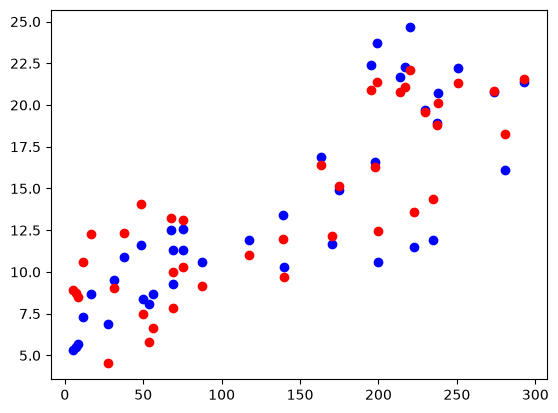

In [13]:
plt.scatter(X_test['TV'], y_test, color='blue')
plt.scatter(X_test['TV'], y_pred, color='red')
plt.show()

In [16]:
model.predict([[230,45,46]])

d:\repositories\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
2026/07/30 18:34:03 WARNING mlflow.sklearn: Unrecognized dataset type <class 'list'>. Dataset logging skipped.


array([21.90764506])

In [31]:
import joblib
joblib.dump(model, '../../Projects/models/sales_model.pkl')

['../../Projects/models/sales_model.pkl']

In [17]:
exp = mlflow.get_experiment("1")
exp.name

'sales_predictor'